In [1]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv, find_dotenv
from langchain_pymupdf4llm import PyMuPDF4LLMLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition
from pathlib import Path


/tmp/ipykernel_4044229/3528905943.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [2]:
load_dotenv(find_dotenv())
gemini_model = os.environ.get("GEMINI_MODEL")

In [3]:
llm = ChatGoogleGenerativeAI(model=gemini_model, temperature=0.7)

In [4]:

# The PDF sits at the project root; the kernel may be started from there or from notebook/
pdf_path = next(
    path.resolve()
    for path in (Path("my_paper.pdf"), Path("../my_paper.pdf"))
    if path.is_file()
)

loader = PyMuPDF4LLMLoader(pdf_path)
docs = loader.load()

In [5]:
docs

[Document(metadata={'producer': 'pdfTeX-1.40.21', 'creator': 'LaTeX with hyperref', 'creationdate': '2021-09-14T02:52:38+00:00', 'source': '/home/kashif/Desktop/learning/fde/agentic-ai/langgraph-code/Agentic-Chatbot-using-LangGraph/my_paper.pdf', 'file_path': '/home/kashif/Desktop/learning/fde/agentic-ai/langgraph-code/Agentic-Chatbot-using-LangGraph/my_paper.pdf', 'total_pages': 15, 'format': 'PDF 1.5', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2021-09-14T02:52:38+00:00', 'trapped': '', 'modDate': 'D:20210914025238Z', 'creationDate': 'D:20210914025238Z', 'page': 0}, page_content='See discussions, stats, and author profiles for this publication at: https://www.researchgate.net/publication/357213035 \n\n# Development of Multiple Combined Regression Methods for Rainfall Measurement Development of Multiple Combined Regression Methods for Rainfall Measurement \n\n\n\n<!-- Start of picture text -->\nArticle  · December 2021<br><!-- End of picture text -->\n\n\n\n

In [6]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [7]:
len(chunks)

58

In [8]:
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")
vectorstore = FAISS.from_documents(chunks, embeddings)
vectorstore.save_local("faiss_index")


In [9]:
vectorstore

In [10]:
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 3})

In [11]:
answer = retriever.invoke("What is Rainfall measurement?")

In [12]:
answer

[Document(id='81c92485-0b06-4c81-837b-c61ed5552f8c', metadata={'producer': 'pdfTeX-1.40.21', 'creator': 'LaTeX with hyperref', 'creationdate': '2021-09-14T02:52:38+00:00', 'source': '/home/kashif/Desktop/learning/fde/agentic-ai/langgraph-code/Agentic-Chatbot-using-LangGraph/my_paper.pdf', 'file_path': '/home/kashif/Desktop/learning/fde/agentic-ai/langgraph-code/Agentic-Chatbot-using-LangGraph/my_paper.pdf', 'total_pages': 15, 'format': 'PDF 1.5', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2021-09-14T02:52:38+00:00', 'trapped': '', 'modDate': 'D:20210914025238Z', 'creationDate': 'D:20210914025238Z', 'page': 3}, page_content='amount of rainfall recorded for the day in mm) and avoid the annihilation caused by it to life, agriculture, farm, and property. If we can quantify the rainfall most people can make some decisions before overwhelmed rain-affected. The contributions of this work are summarised as:'),
 Document(id='572bdb2e-cdd1-4cb9-b2b2-97e565f54c51', meta

In [13]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve the most relevant documents from the vector store based on the query. Use this tool when the user asks about the content of the PDF.
    Input should be a valid query.
    Example: "What is Rainfall measurement?"
    
    Args:
        query: The query to retrieve the most relevant documents from the vector store.
    Returns:
        The most relevant documents from the vector store in a list of strings.
    """
    documents = retriever.invoke(query)

    if not documents:
        return "No Relevant documents found for the query."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown")
        page = document.metadata.get("page", "Unknown")
        formatted_documents.append(
            f"Document {index} \n Source: {source} \n Page: {page} \n Content: {document.page_content}")


    return "\n".join(formatted_documents)

In [14]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [15]:
llm_with_tools

_ChatModelBinding(bound=ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.8.3', 'langchain': '1.5.2', 'langchain-google-genai': '4.5.1'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', client=<google.genai.client.Client object at 0x7425e5af0690>, default_metadata=(), model_kw

In [16]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [17]:
def chat_node(state: ChatState):
    """LLM node that may answer or use tools based on the user's input."""
    messages = state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)

In [18]:
graph = StateGraph(ChatState)
graph.add_node("tools", tool_node)
graph.add_node("chat_node", chat_node)
graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", tools_condition)
graph.add_edge("tools", "chat_node")
chatbot = graph.compile()


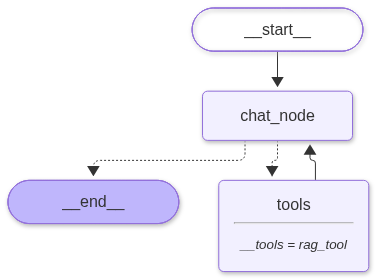

In [19]:
chatbot

In [20]:
result = chatbot.invoke({"messages": [HumanMessage(content="What is Rainfall measurement?")]})

/home/kashif/Desktop/learning/fde/agentic-ai/langgraph-code/Agentic-Chatbot-using-LangGraph/.venv/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [21]:
print(result["messages"][-1].text)

Based on the provided document, **rainfall measurement** involves recording and quantifying the amount of precipitation (typically measured in millimeters, **mm**) for a given day or period. 

Quantifying rainfall helps people, farmers, and authorities make informed decisions and take precautions to prevent or mitigate the damage caused by heavy rains and flooding to life, agriculture, farms, and property. 

However, researchers (such as John C. Rodda) have noted that ordinary methods of estimating precipitation can contain systematic errors or mistakes that can affect gauges utilizing those measurements.


In [22]:
result = chatbot.invoke({"messages": [HumanMessage(content="hello, how are you?")]})

In [23]:
result["messages"][-1].text

"Hello! I'm doing well, thank you for asking. How can I help you today?"